# Proyecto Xi: Predicción del Valor de Mercado de Vehículos Usados

## Descripción del Proyecto

Rusty Bargain es un servicio de venta de vehículos usados que desea desarrollar una aplicación capaz de estimar rápidamente el valor de mercado de un automóvil a partir de sus características.

El objetivo de este proyecto es construir y comparar diversos modelos de aprendizaje automático para predecir el precio de vehículos usados utilizando información histórica, especificaciones técnicas y características del vehículo.

## Objetivos

- Predecir el precio de vehículos usados con la menor cantidad de error posible.
- Comparar diferentes algoritmos de regresión.
- Evaluar el desempeño de cada modelo mediante la métrica RMSE.
- Comparar:
    - Calidad de predicción.
    - Tiempo de entrenamiento.
    - Velocidad de predicción.

## Modelos a Evaluar

1. Regresión Lineal (Baseline)
2. Árbol de Decisión
3. Regresión lineal
4. Bosque Aleatorio (Random Forest)
5. LightGBM
6. CatBoost
7. XGboost

## Métrica de Evaluación

Se utilizará la métrica **RMSE (Root Mean Squared Error)** para evaluar la calidad de los modelos.

## Etapas del Proyecto

1. Carga y exploración de datos.
2. Limpieza y preprocesamiento.
3. Análisis exploratorio.
4. Preparación de características.
5. Entrenamiento de modelos.
6. Ajuste de hiperparámetros.
7. Comparación de resultados.
8. Conclusiones y recomendación para Rusty Bargain.

Estructura general del dataset

Características

DateCrawled — fecha en la que se descargó el perfil de la base de datos.


VehicleType — tipo de carrocería del vehículo.


RegistrationYear — año de matriculación del vehículo.


Gearbox — tipo de caja de cambios.


Power — potencia (CV).


Model — modelo del vehículo.


Mileage — kilometraje (medido en km de acuerdo con las especificidades regionales del conjunto de datos).


RegistrationMonth — mes de matriculación del vehículo.


FuelType — tipo de combustible.


Brand — marca del vehículo.


NotRepaired — vehículo con o sin reparación.


DateCreated — fecha de creación del perfil.


NumberOfPictures — número de fotos del vehículo.


PostalCode — código postal del propietario del perfil (usuario).


LastSeen — fecha de la última vez que el usuario estuvo activo.


Objetivo
Price — precio (en euros)

Primeramente importamos nuestro dataset a nuestro entorno de trabajo

In [ ]:
import pandas as pd

coches = pd.read_csv("/content/car_data.csv")

Procedemos a a realizar una exploración básica general sobre su contenido

In [ ]:
coches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Mileage            354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  NotRepaired        283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

En este dataset podemos darnos cuenta que contamos con 16 columnas, en las cuales contenemos datos de numéricos enteros de tipo int64, o datos de tipo object que podrían representar texto o mezclas de datos, también podemos observar valores ausentes en algunas columnas las cuales serán analizadas con más detalle.

También podemos ver que las columnas
DateCrawled, DateCreated y LastSeen de tipo object representa la fecha de creación del perfil, por lo que nuestro primer paso será convertirlo a una columna de tipo fecha.

In [ ]:
coches.sample(10)

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
56333,05/03/2016 14:13,5850,wagon,2005,manual,140,a4,150000,3,gasoline,audi,no,03/03/2016 00:00,0,56472,26/03/2016 06:45
245732,21/03/2016 08:56,4250,coupe,1983,auto,0,s_klasse,150000,2,petrol,mercedes_benz,NaN,21/03/2016 00:00,0,46446,25/03/2016 05:45
60620,08/03/2016 14:38,749,sedan,1993,manual,122,c_klasse,150000,11,petrol,mercedes_benz,NaN,08/03/2016 00:00,0,55777,23/03/2016 19:16
200819,24/03/2016 15:54,15950,NaN,2017,manual,122,a1,60000,7,petrol,audi,NaN,24/03/2016 00:00,0,94107,06/04/2016 20:44
102040,01/04/2016 19:55,1000,small,1998,manual,52,clio,150000,9,petrol,renault,no,01/04/2016 00:00,0,31608,05/04/2016 16:45
228064,29/03/2016 19:52,500,sedan,1999,manual,90,carisma,150000,3,petrol,mitsubishi,yes,29/03/2016 00:00,0,31582,29/03/2016 19:52
96456,31/03/2016 19:49,7300,sedan,2004,manual,116,1er,30000,12,petrol,bmw,no,31/03/2016 00:00,0,47139,06/04/2016 14:17
241195,17/03/2016 14:36,2500,wagon,2001,manual,110,golf,150000,10,gasoline,volkswagen,no,17/03/2016 00:00,0,66424,17/03/2016 15:43
345300,14/03/2016 12:53,590,small,1997,manual,60,fiesta,150000,7,petrol,ford,no,14/03/2016 00:00,0,73733,14/03/2016 13:40
317560,17/03/2016 10:51,1420,sedan,1993,manual,0,NaN,150000,0,petrol,audi,no,17/03/2016 00:00,0,35794,18/03/2016 21:29


In [ ]:
date_columns = ["DateCrawled", "DateCreated", "LastSeen"]

coches[date_columns] = coches[date_columns].apply(lambda col: pd.to_datetime(col, dayfirst=True))

In [ ]:
coches[["DateCrawled", "DateCreated", "LastSeen"]].dtypes

,0
DateCrawled,datetime64[ns]
DateCreated,datetime64[ns]
LastSeen,datetime64[ns]


Una vez corregidos los tipos de datos correspondientes a las variables temporales, procedemos a analizar la presencia de valores ausentes dentro del conjunto de datos.

Para ello se calcula tanto la cantidad como el porcentaje de valores faltantes en cada columna, lo que permitirá determinar la magnitud del problema y definir posteriormente la estrategia de tratamiento más adecuada para cada variable.

In [ ]:
# Cantidad de valores ausentes por columna

conteo_faltantes = coches.isna().sum().sort_values(ascending=False)

# Porcentaje de valores ausentes por columna

porcentaje_faltantes = (
    coches.isna().sum()
    / len(coches)
    * 100
).sort_values(ascending=False)

# Tabla resumen

valores_faltantes = pd.DataFrame({
    'conteo_faltantes': conteo_faltantes,
    'porcentaje_faltantes': porcentaje_faltantes
})

valores_faltantes

,conteo_faltantes,porcentaje_faltantes
NotRepaired,71154,20.079070
VehicleType,37490,10.579368
FuelType,32895,9.282697
Gearbox,19833,5.596709
Model,19705,5.560588
Price,0,0.000000
RegistrationYear,0,0.000000
DateCrawled,0,0.000000
Mileage,0,0.000000
Power,0,0.000000


Se identificaron valores ausentes únicamente en variables categóricas. Debido a que algunas columnas presentan una cantidad considerable de registros faltantes, especialmente NotRepaired (20.08%), eliminar las filas correspondientes provocaría una pérdida importante de información.

Dado que el desconocimiento de una característica también puede aportar información al modelo, se decidió imputar los valores ausentes utilizando la categoría "desconocido". Esta estrategia permite conservar todos los registros del conjunto de datos y facilita el procesamiento posterior por parte de los algoritmos de aprendizaje automático.

In [ ]:
columnas_valores_faltantes = ["NotRepaired", "VehicleType", "FuelType", "Gearbox", "Model"]

coches[columnas_valores_faltantes] = coches[columnas_valores_faltantes].fillna("desconocido")

Confirmamos el correcto tratamiento de los valores ausentes en el dataset.

In [ ]:
coches.isna().sum()

,0
DateCrawled,0
Price,0
VehicleType,0
RegistrationYear,0
Gearbox,0
Power,0
Model,0
Mileage,0
RegistrationMonth,0
FuelType,0


Una vez tratados los valores ausentes, se procedió a verificar la existencia de registros duplicados. La presencia de observaciones repetidas puede introducir sesgos en el análisis y afectar el desempeño de los modelos de aprendizaje automático, por lo que resulta importante identificarlas y tratarlas antes de continuar con la preparación de los datos.

In [ ]:
coches.duplicated().sum()

np.int64(262)

Observamos el porcentaje de valores duplicados en todo el dataset

In [ ]:
porcentaje_valores_duplicados = 262 / 354369 * 100
print("el porcentaje de valores duplicados en todo el dataset es del", porcentaje_valores_duplicados, "%")

el porcentaje de valores duplicados en todo el dataset es del 0.07393423239617461 %


Como podemos observar el porcentaje de valores faltantes para todo nuestro conjunto de datos principal es de alrededor del 0.07%, un porcentaje que no consideramos importante o significativo para poder eliminar.

In [ ]:
coches = coches.drop_duplicates()
coches.duplicated().sum()

np.int64(0)

Tras corregir los valores ausentes y eliminar los registros duplicados, se procede a analizar las variables numéricas más relevantes para identificar posibles valores anómalos.

Se prestará especial atención a las variables Price, RegistrationYear y Power, ya que representan características fundamentales del vehículo y podrían contener registros erróneos o inconsistentes que afecten negativamente el entrenamiento de los modelos.

In [ ]:
coches.describe()

,DateCrawled,Price,RegistrationYear,Power,Mileage,RegistrationMonth,DateCreated,NumberOfPictures,PostalCode,LastSeen
count,354107,354107.000000,354107.000000,354107.000000,354107.000000,354107.000000,354107,354107.0,354107.000000,354107
mean,2016-03-21 12:56:48.735947008,4416.433287,2004.235355,110.089651,128211.811684,5.714182,2016-03-20 19:11:13.738728960,0.0,50507.145030,2016-03-29 23:51:12.374903808
min,2016-03-05 14:06:00,0.000000,1000.000000,0.000000,5000.000000,0.000000,2014-03-10 00:00:00,0.0,1067.000000,2016-03-05 14:15:00
25%,2016-03-13 11:52:00,1050.000000,1999.000000,69.000000,125000.000000,3.000000,2016-03-13 00:00:00,0.0,30165.000000,2016-03-23 02:50:00
50%,2016-03-21 17:50:00,2700.000000,2003.000000,105.000000,150000.000000,6.000000,2016-03-21 00:00:00,0.0,49406.000000,2016-04-03 15:15:00
75%,2016-03-29 14:36:00,6400.000000,2008.000000,143.000000,150000.000000,9.000000,2016-03-29 00:00:00,0.0,71083.000000,2016-04-06 10:06:00
max,2016-04-07 14:36:00,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,2016-04-07 00:00:00,0.0,99998.000000,2016-04-07 14:58:00
std,NaN,4514.338584,90.261168,189.914972,37906.590101,3.726682,NaN,0.0,25784.212094,NaN


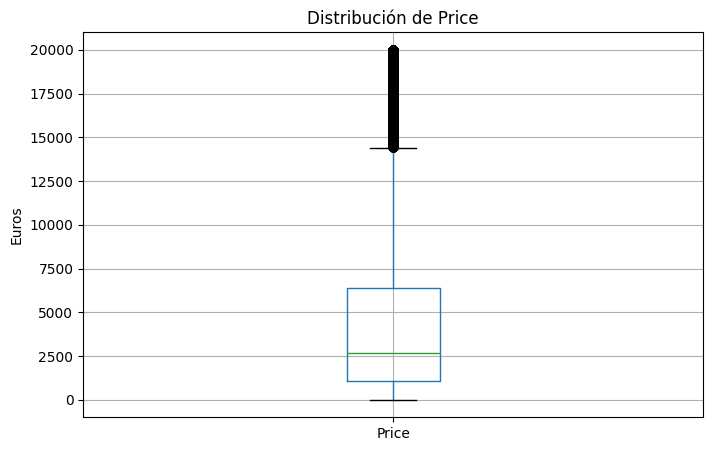

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
coches.boxplot(column="Price")
plt.title("Distribución de Price")
plt.ylabel("Euros")
plt.show()

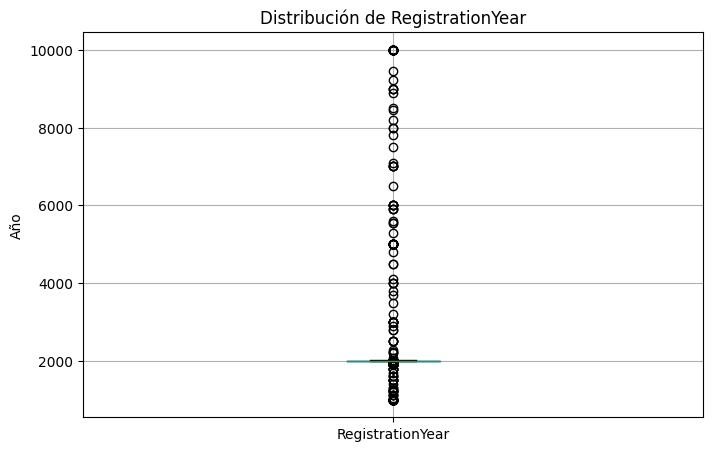

In [ ]:
plt.figure(figsize=(8, 5))
coches.boxplot(column="RegistrationYear")
plt.title("Distribución de RegistrationYear")
plt.ylabel("Año")
plt.show()

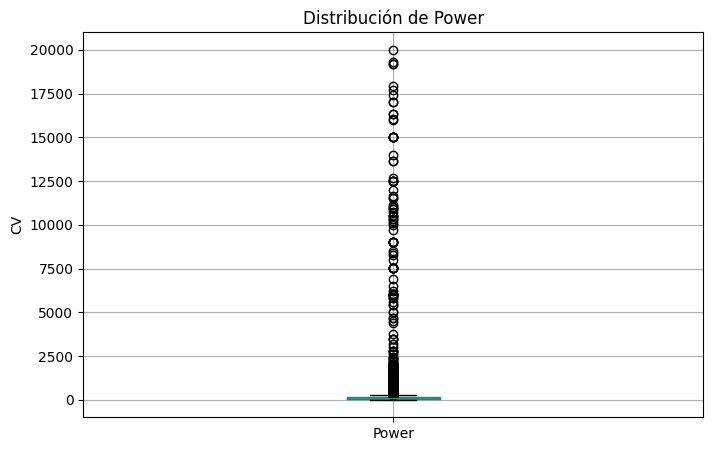

In [ ]:
plt.figure(figsize=(8, 5))
coches.boxplot(column="Power")
plt.title("Distribución de Power")
plt.ylabel("CV")
plt.show()

En este momento podemos observar datos bastante anómalos, por ejemplo podemos ver que la columna de precios indica un valor mínimo existente de 0.0000, lo que nos podría indicar error en los registros.

En la columna de año de registro (RegistrationYear) podemos observar valores como 1000.000000 o 9999.000000, claramente valores que no presentan sentido alguno.

Para la columna de poder medido en caballos de vapor (CV) se registran datos erroneos de 0.0000,que también tomamos como dato erróneo.

Por último, para la columna de mes de matriculación del vehículo se observa como valor mínimo 0.0000, un dato que también podríamos considerar como inacertado.



In [ ]:
coches.sample(4)

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
261278,2016-03-31 19:41:00,650,sedan,1992,manual,115,3er,150000,11,petrol,bmw,yes,2016-03-31,0,69181,2016-03-31 19:41:00
289576,2016-03-22 20:36:00,13499,sedan,2012,manual,122,golf,80000,3,petrol,volkswagen,no,2016-03-22,0,72178,2016-04-06 16:17:00
130185,2016-04-03 19:51:00,4350,desconocido,2017,manual,60,polo,90000,11,desconocido,volkswagen,no,2016-04-03,0,2791,2016-04-05 20:45:00
245885,2016-03-07 19:40:00,9950,sedan,2007,manual,177,5er,150000,1,gasoline,bmw,no,2016-03-07,0,52445,2016-03-24 17:15:00


Ahora procederemos a generar un conteo de los valores anómalos en las columnas analizadas, con esta información podemos tener una mejor noción del tipo  de filtrados que podemos aplicar para conseguir datos óptimos para nuestros análisis y modelados posteriores.

In [ ]:
año_registro_anomalo = coches.loc[
    (coches["RegistrationYear"] < 1900) |
    (coches["RegistrationYear"] > 2016),
    "RegistrationYear"
].count()

In [ ]:
potencia_anomala = coches.loc[
    coches["Power"] == 0,
    "Power"
].count()

In [ ]:
precios_anomalos = coches.loc[
    coches["Price"] == 0,
    "Price"
].count()

In [ ]:
mes_registro_anomalo = coches.loc[coches["RegistrationMonth"] == 0, "RegistrationMonth"].count()

In [ ]:
# Generación de un dataframe con esta información registrada
datos_anomalos = pd.DataFrame({"Datos Anómalos de precio": [precios_anomalos], "Potencia anómala": [potencia_anomala], "Año de registro anomalo": [año_registro_anomalo], "Mes de registro anómalo": [mes_registro_anomalo]})

print(datos_anomalos)

   Datos Anómalos de precio  Potencia anómala  Año de registro anomalo  \
0                     10770             40218                    14595   

   Mes de registro anómalo  
0                    37347  


Se identificaron registros con precios iguales a cero, potencias iguales a cero y años de matriculación imposibles. Debido a que estos valores no representan características válidas de un vehículo y podrían afectar negativamente el entrenamiento de los modelos, se decidió eliminarlos del conjunto de datos.

En cuanto a RegistrationMonth, aunque el valor 0 no corresponde a un mes válido, podría representar información desconocida. Por esta razón, esta variable se mantendrá sin modificaciones en esta etapa.

Procedemos a limpiar el dataset principal aplicando los filtros necesarios construídos para dejar fuera los valores extremos que no presentan valor o lógica para la estructura.

In [ ]:
coches = coches[
    (coches["Price"] > 0) &
    (coches["Power"] > 0) &
    (coches["RegistrationYear"] >= 1900) &
    (coches["RegistrationYear"] <= 2016)
]

Confirmamos los cambios en el dataset

In [ ]:
coches[["Price", "Power", "RegistrationYear"]].describe()

,Price,Power,RegistrationYear
count,296646.000000,296646.000000,296646.000000
mean,4853.133745,124.293265,2002.813529
std,4611.788715,190.895091,6.560125
min,1.000000,1.000000,1910.000000
25%,1349.000000,75.000000,1999.000000
50%,3200.000000,111.000000,2003.000000
75%,6999.000000,150.000000,2007.000000
max,20000.000000,20000.000000,2016.000000


Analizando el contenido estadístico de nuestro dataset podemos observar nueva información a la cual debemos prestar atención:

1 El valor de precio mínimo corresponde a 1 euro

2 La potencia mínima de caballos de vapor es de 1

3 La potencia máxima se registra en 20.0000 caballos de vapor

Estos datos nuevamente se presentan como valores extremos, por lo que debereremos analizarlos y tratarlos adecuadamente.

In [ ]:
coches["Power"].describe(percentiles=[0.95, 0.99, 0.995])

,Power
count,296646.000000
mean,124.293265
std,190.895091
min,1.000000
50%,111.000000
95%,224.000000
99%,306.000000
99.5%,340.000000
max,20000.000000


Podemos observar que el 99.5% de los valores se encuentran en valores que rondan o estan por debajo de los 340 caballos de vapor de potencia, el valor máximo aún lo podemos percibir en 20.000 caballos de vapor de potencia, un valor sin duda desproporcionado tomando en cuenta que dichas potencias solo se ven en maquinarias muy complejas o de exigencias deportivas. Sin duda este valor tan extremo no pertenece a nuestro dataset.

Sin lugar a dudas podemos valernos del dato que tenemos del 99.5% de los valores en nuestro dataset, el hecho de que estos 20.000 CV no se repitan en un porcentaje mayor nos rectifica la naturaleza errónea de su indexación en esta columna.

Tomando lo anterior mencionado en cuenta, procederemos a eliminar las fials que contengan esos valores.

In [ ]:
coches = coches[coches["Power"] <= 340]

Observamos nuevamente las actualizaciones estadísticas

In [ ]:
coches["Power"].describe()

,Power
count,295228.000000
mean,119.570278
std,51.273008
min,1.000000
25%,75.000000
50%,110.000000
75%,150.000000
max,340.000000


Con los valores anómalos eliminados podemos confirmar que para la potencia máxima de los vehículos adoptamos valores estables y congruentes.

Sin embargo podemos ver un valor igualmente anómalo para sus índices mínimos (exáctamente de 1) por lo que procederemos a analizar los percentiles de mayor relevancia para determinar que tan frecuente resulta este valor.


In [ ]:
coches["Power"].describe(percentiles = [0.95, 0.99, 0.995, 0.45, 0.35, 0.01, 0.000001])

,Power
count,295228.000000
mean,119.570278
std,51.273008
min,1.000000
0.0001%,1.000000
1%,45.000000
35%,95.000000
45%,105.000000
50%,110.000000
95%,218.000000


Esta vez recurrimos a parcentiles más extremos para determinar con mejor presición la recurrencia con la que el valor de 1 CV aparece en nuestra columna.

Si hablamos del 1% de nuestros datos, podemos observar potencias que igualan o rondan los 45 CV. Pero al revisar que porcentaje rondan los valores de 1 CV podemos notar que al rededor del 0.0001% cubren esos valores.

Con esto confirmamos que dichas apariciones de datos tan anormalmente bajos no se deben a indexaciones premediatadas o justificadas, lo cual nos permite eliminar dichos datos.

In [ ]:
(coches["Power"] == 1).sum()

np.int64(26)

In [ ]:
coches = coches[coches["Power"] > 1]
coches["Power"].describe()

,Power
count,295202.000000
mean,119.580721
std,51.263189
min,2.000000
25%,75.000000
50%,110.000000
75%,150.000000
max,340.000000


In [ ]:
datos_anomalos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Datos Anómalos de precio  1 non-null      int64
 1   Potencia anómala          1 non-null      int64
 2   Año de registro anomalo   1 non-null      int64
 3   Mes de registro anómalo   1 non-null      int64
dtypes: int64(4)
memory usage: 164.0 bytes


Ahora procederemos a analizar la columnas de precio

In [ ]:
coches["Price"].describe(percentiles = (0.99, 0.80, 0.50, 0.30, 0.10, 0.05, 0.01, 0.0001))

,Price
count,295202.000000
mean,4825.206570
std,4584.091911
min,1.000000
0.01%,1.000000
1%,150.000000
5%,450.000000
10%,650.000000
30%,1600.000000
50%,3190.000000


De la misma forma que en el caso anterior, usamos variados y precisos percentiles para obervar de forma más acertada con que frecuencia aparecen los datos anómalos.

En esta ocasión podemos observar que ni en el 1% de la totalidad de nuestros datos tenemos valores que ronden por el precio extremadamente bajo de un euro. Según nuestra información estadística en el 0.01% de la totalidad de nuestra columna se muestra este valor.



Ahora cuantificaremos la cantidad de vehiculos que resgistran este precio anómalo

In [ ]:
(coches["Price"] == 1).sum() / len(coches) * 100

np.float64(0.2198494590145053)

Determinamos que la frecuencia con la que se resgistran precios de 1 euro en nuestra columna es de alrededor del 0.2%, un valor que consideramos como irrelevante para el modelado posterior.

Con esto en consideración podemos eliminar dichas filas ya que no impactaran de forma importante contenido crítico de nuestro dataset

In [ ]:
coches = coches[coches["Price"] > 1]

Por último trataremos la columna que nos detalla el mes de registro

In [ ]:
coches["RegistrationMonth"].describe(percentiles = [0.99, 0.80, 0.50, 0.30, 0.10, 0.05, 0.01, 0.0001])

,RegistrationMonth
count,294553.000000
mean,5.994914
std,3.582854
min,0.000000
0.01%,0.000000
1%,0.000000
5%,0.000000
10%,1.000000
30%,4.000000
50%,6.000000


In [ ]:
(coches["RegistrationMonth"] == 0).sum() / len(coches) * 100

np.float64(6.0298146683279406)

Para el mes de registro con indexación igual a 0 observamos que la frecuencia de su aparición está ubicada por el 6.02 %, un valor claramente alto el cual des ser eliminado sustraería un gran porcentaje de filas de neustro dataset principal, por lo que en vez de eliminarlas procederemos a analizar a mayor detalle las filas que lo contienen

In [ ]:
coches.loc[coches["RegistrationMonth"] == 0].head(10)

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
9,2016-03-17 10:53:00,999,small,1998,manual,101,golf,150000,0,desconocido,volkswagen,desconocido,2016-03-17,0,27472,2016-03-31 17:17:00
16,2016-04-01 12:46:00,300,desconocido,2016,desconocido,60,polo,150000,0,petrol,volkswagen,desconocido,2016-04-01,0,38871,2016-04-01 12:46:00
36,2016-03-11 11:50:00,1600,other,1991,manual,75,kadett,70000,0,desconocido,opel,desconocido,2016-03-11,0,2943,2016-04-07 03:46:00
80,2016-04-01 22:39:00,250,wagon,2000,manual,155,156,150000,0,petrol,alfa_romeo,yes,2016-04-01,0,8396,2016-04-05 20:18:00
92,2016-03-16 07:56:00,250,desconocido,2000,desconocido,60,ka,150000,0,desconocido,ford,desconocido,2016-03-16,0,51427,2016-03-21 09:47:00
104,2016-03-20 12:59:00,300,convertible,1992,manual,105,escort,150000,0,desconocido,ford,yes,2016-03-20,0,88515,2016-04-06 13:15:00
129,2016-03-26 19:37:00,300,small,2000,manual,54,corsa,150000,0,petrol,opel,desconocido,2016-03-26,0,59379,2016-04-06 09:15:00
135,2016-03-27 20:51:00,1450,sedan,1992,manual,136,desconocido,150000,0,desconocido,audi,no,2016-03-27,0,38709,2016-04-05 20:17:00
143,2016-03-14 12:46:00,1500,wagon,1996,manual,126,a4,150000,0,desconocido,audi,no,2016-03-14,0,24873,2016-03-17 00:45:00
168,2016-04-01 10:54:00,950,sedan,1995,manual,115,5er,150000,0,petrol,bmw,desconocido,2016-04-01,0,27751,2016-04-07 07:46:00


Con estos detalles mejor analizados podemos determinar que la aparición de un valor de 0 en el mes de registro no parece error o descuido al momento de la indexación.


En este momento procederemos a revisar nuevamente con que columnas dispone nuestro dataset principal. Verificaremos cuales aportan valor real ya que la construcción de nuestro modelo independientemente del algoritmo que usemos perderá eficiencia al trabajar con características que no generarían patrones reales o que causarían ruido inneceario

In [ ]:
coches.columns

Index(['DateCrawled', 'Price', 'VehicleType', 'RegistrationYear', 'Gearbox',
       'Power', 'Model', 'Mileage', 'RegistrationMonth', 'FuelType', 'Brand',
       'NotRepaired', 'DateCreated', 'NumberOfPictures', 'PostalCode',
       'LastSeen'],
      dtype='object')

De nuestras columnas encontramos 5 las cuales no aportan valor al modelado el cual busca predecir el valor de un coche en el mercado.

DateCrawled — fecha en la que se descargó el perfil de la base de datos.

DateCreated — fecha de creación del perfil.

NumberOfPictures — número de fotos del vehículo.

PostalCode — código postal del propietario del perfil (usuario).

LastSeen — fecha de la última vez que el usuario estuvo activo.


Esto debido a que por si solas o en conjunto no determinan el valor de un vehículo, el propietario del perfil habría podido estar activo recientemente o desde hace mucho, son hechos que no tienen relevancia a la hora de determinar el valor del vehículo.

Naturalmente descartamos la posibilidad de manipular o "limpiar" estas carácterísticas dado que no presentan inconsistencias o valores atípicos. Pero desde ahora se consideran irrelevantes en nuestro modelado, por lo que procederemos a eliminarlas de nuestro dataset principal.

In [ ]:
coches_limpio = coches.drop(["DateCrawled", "DateCreated", "NumberOfPictures", "PostalCode",  "LastSeen"], axis = 1).copy()

In [ ]:
coches_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 294553 entries, 1 to 354368
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   Price              294553 non-null  int64 
 1   VehicleType        294553 non-null  object
 2   RegistrationYear   294553 non-null  int64 
 3   Gearbox            294553 non-null  object
 4   Power              294553 non-null  int64 
 5   Model              294553 non-null  object
 6   Mileage            294553 non-null  int64 
 7   RegistrationMonth  294553 non-null  int64 
 8   FuelType           294553 non-null  object
 9   Brand              294553 non-null  object
 10  NotRepaired        294553 non-null  object
dtypes: int64(5), object(6)
memory usage: 27.0+ MB


Procedemos a definir nuestras característica y nuestra variable objetivo

In [ ]:
caracteristicas = coches_limpio.drop(["Price"], axis = 1)

objetivo = coches_limpio["Price"]

Ahora separaremos nuestro dataset principal en conjuntos de entrenamiento, prueba y validación.

In [ ]:
# Primero dividimos nuestro dataset en un 60% entrenamiento y un 40% prueba
from sklearn.model_selection import train_test_split

caracteristicas_entrenamiento, caracteristicas_prueba, objetivo_entrenamiento, objetivo_prueba = train_test_split(caracteristicas, objetivo, test_size = 0.4, random_state = 12345, shuffle = True)

# Después dividimos el 50% de nuestro dataset de prueba para separar nuestro dataset de validación

caracteristicas_validacion, caracteristicas_prueba, objetivo_validacion, objetivo_prueba = train_test_split(caracteristicas_prueba, objetivo_prueba, test_size = 0.5, random_state = 12345, shuffle = True)

Verificamos que los tamaños sean los apropiados

In [ ]:
caracteristicas_entrenamiento.shape

(176731, 10)

In [ ]:
caracteristicas_prueba.shape

(58911, 10)

In [ ]:
caracteristicas_validacion.shape

(58911, 10)

In [ ]:
coches_limpio.shape

(294553, 11)

Con esta información podemos confirmar que organizamos en las proporciones adecuadas nuestro conjunto de entrenamiento, prueba y validación.

Ahora nuestro objetivo es tratar las variables categóricas de nuestrso distintos conjuntos, ya que varios modelos que construiremos más adelante se ven afectados en gran medida por la naturaleza de dichos datos.

En este momento recurriremos a la implementación del One Hot Encoding para tratar nuestras variables categóricas evitando la trampa dummy

In [ ]:
caracteristicas_entrenamiento_categorias = pd.get_dummies(caracteristicas_entrenamiento, columns = ["VehicleType", "Gearbox",  "Model", "FuelType", "Brand", "NotRepaired"], drop_first = True)
caracteristicas_prueba_categorias = pd.get_dummies(caracteristicas_prueba, columns = ["VehicleType", "Gearbox",  "Model", "FuelType", "Brand", "NotRepaired"], drop_first = True)
caracteristicas_validacion_categorias = pd.get_dummies(caracteristicas_validacion, columns = ["VehicleType", "Gearbox",  "Model", "FuelType", "Brand", "NotRepaired"], drop_first = True)

In [ ]:
print(caracteristicas_entrenamiento_categorias.shape)
print(caracteristicas_validacion_categorias.shape)
print(caracteristicas_prueba_categorias.shape)

(176731, 311)
(58911, 306)
(58911, 307)


Después de la implementación del One Hot Encoding podemos ver que las dimensiones, más específicamente en las columnas de nuestros conjuntos que presentan variables categóricas presentan discrepancias en las cantidades y muy posiblemente en los tipos de datos convertidos.

Es algo que podemos considerar como normal después de ejecutar train_test_split y el One Hot Encoding. Sin embargo es algo que debemos tratar ya que nuestros modelos pueden entrenarse con datos con los cuales no podría toparse después en nuestros conjuntos de prueba y validación.

In [ ]:
caracteristicas_prueba_categorias = caracteristicas_prueba_categorias.reindex(columns = caracteristicas_entrenamiento_categorias.columns, fill_value = 0)
caracteristicas_validacion_categorias = caracteristicas_validacion_categorias.reindex(columns = caracteristicas_entrenamiento_categorias.columns, fill_value = 0)

In [ ]:
print(caracteristicas_entrenamiento_categorias.shape)
print(caracteristicas_prueba_categorias.shape)
print(caracteristicas_validacion_categorias.shape)

(176731, 311)
(58911, 311)
(58911, 311)


Ahora podemos confirmar que nuestros conjuntos de datos comparten las mismas columnas y clases categóricas.



En este momento procederemos a construir un modelo sencillo que de forma premeditada nos dará un resultado de predicción repetido e igualitario. el objetivo de este modelo (que será construído bajo el algoritmo de regresión lineal, ideal para este proyecto de valores constantes) es darnos un punto con el cual podemos comparar el resultado de los demás modelos. Veremos si nuestros modelos aprendieron de forma efectiva o solo hacen predicciones tan malas como este modelo de repetición.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

modelo_base = DummyRegressor(strategy = "mean")

modelo_base.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

prediccion_base = modelo_base.predict(caracteristicas_prueba_categorias)

RECM = root_mean_squared_error(objetivo_prueba, prediccion_base)

print("La raíz media del error cuadrático promedio es de:", RECM)

La raíz media del error cuadrático promedio es de: 4562.247661708443


Este modelo de referencia está construído para dar predicciones repetidas en base al valor medio que presenta nuestra variable objetivo.

Cualquier modelo futuro que construyamos en este proyecto será comparado directamente con sus resultados.

Un modelo que presente un RECM superiór a 4562.24 será considerado como defectuoso al no superar predicciones basadas en una pobre estrategia de repetición.

Construcción del modelo basado en un algoritmo de regresión lineal

In [ ]:
%%time

from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

modelo_lineal = LinearRegression()

modelo_lineal.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

prediccion_modelo_lineal = modelo_lineal.predict(caracteristicas_prueba_categorias)

RECM_modelo_lineal = root_mean_squared_error(objetivo_prueba, prediccion_modelo_lineal)

print("la raíz del error cuadrático promedio del modelo de regresión lineal es de:", RECM_modelo_lineal)

la raíz del error cuadrático promedio del modelo de regresión lineal es de: 2554.63422553726
CPU times: user 11.4 s, sys: 539 ms, total: 11.9 s
Wall time: 8.53 s


Con el resultado de nuestro primer modelo podemos confirmar que el modelo verdaderamente aprendio patrones útiles ya que obtuvimos una raíz del error cuadrático promedio de 2554.63 euros, un valor claramente inferiór (casi de la mitad) al de nuestro modelo base.

Obtuvimos además la predicción del modelo lineal en aproximádamente 8.47 segundos.

Construcción del modelo basado en un algoritmo de árbol de decisión para regresión



In [ ]:
import numpy as np
semilla = np.random.seed(12)

In [55]:
%%time

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

mejor_modelo_arbol = None
mejor_profundidad_arbol = 0
mejor_muestras_hoja_arbol = 0
mejor_resultado_RECM_arbol = 4562.24

semilla = 12

for profundidad in range(1, 60, 2):
    for hojas in range (1, 10, 1):

        modelo_arbol = DecisionTreeRegressor(max_depth = profundidad, random_state = semilla, min_samples_leaf = hojas, ccp_alpha = 0.01)

        modelo_arbol.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

        prediccion_arbol = modelo_arbol.predict(caracteristicas_prueba_categorias)

        RECM_modelo_arbol = root_mean_squared_error(objetivo_prueba, prediccion_arbol)

        if RECM_modelo_arbol < mejor_resultado_RECM_arbol:
            mejor_modelo_arbol = modelo_arbol
            mejor_profundidad_arbol = profundidad
            mejor_muestras_hoja_arbol = hojas
            mejor_resultado_RECM_arbol = RECM_modelo_arbol

print("El mejor modelo basado en un algoritmo de árbol de decisión para regresión es: ", mejor_modelo_arbol)
print()
print()
print("La mejor profundidad de nuestro árbol es de: ", mejor_profundidad_arbol, "niveles")
print()
print()
print("La cantidad mínima de muestras de ejemplo para las hojas es de: ", mejor_muestras_hoja_arbol)
print()
print()
print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo es de: ", mejor_resultado_RECM_arbol)



El mejor modelo basado en un algoritmo de árbol de decisión para regresión es:  DecisionTreeRegressor(ccp_alpha=0.01, max_depth=27, min_samples_leaf=9,
                      random_state=12)


La mejor profundidad de nuestro árbol es de:  27 niveles


La cantidad mínima de muestras de ejemplo para las hojas es de:  9


El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo es de:  1746.3747305753573
CPU times: user 25min 39s, sys: 28.5 s, total: 26min 7s
Wall time: 26min 27s


Con este resultado obtenemos un óptimo modelo de árbol de decisión para regresión con las siguientes características de hiperparámetros:

1 La mejor profundidad fué resgistrada en 27 niveles.

2 La mejor cantidad de muestras para cada hoja se registró en 9.

3 La raíz del error cuadrático medio se registró por un valor de 1746.37 euros.

4 El tiempo de ejecución del modelo para encontrar sus más eficientes hiperparámetros se registró por 25 minutos con 33 segundos

Este valor RECM lo consideramos inferior a nuestro modelo base (RECM = 4562.24 euros), también lo consideramos inferior y por lo tanto mejor a nuestro modelo de regresión lineal (RECM = 2554.63 euros).




Construcción del modelo basado en un algoritmo de bosque aleatorio

In [60]:
%%time

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

mejor_modelo_bosque = None
mejor_cantidad_arboles = 0
mejor_profundidad_arboles_bosque = 0
mejor_hojas_bosque = 0
mejor_resultado_RECM_bosque = 4562.24

for arboles in [50, 100, 200]:
    for profundidad in [10, 15, 20]:
        for hojas in [1, 5]:

            modelo_bosque = RandomForestRegressor(random_state = 12, n_estimators = arboles, max_depth = profundidad, n_jobs = -1, min_samples_leaf = hojas, ccp_alpha = 0.01)

            modelo_bosque.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

            prediccion_bosque = modelo_bosque.predict(caracteristicas_prueba_categorias)

            RECM_bosque = root_mean_squared_error(objetivo_prueba, prediccion_bosque)

            if RECM_bosque < mejor_resultado_RECM_bosque:

                mejor_modelo_bosque = modelo_bosque
                mejor_cantidad_arboles = arboles
                mejor_profundidad_arboles_bosque = profundidad
                mejor_hojas_bosque = hojas
                mejor_resultado_RECM_bosque = RECM_bosque


print("El mejor modelo basado en un algoritmo de bosque aleatorio para regresión es: ", mejor_modelo_bosque)
print()
print()
print("La mejor cantidad de árboles para nuestro bosque es de: ", mejor_cantidad_arboles)
print()
print()
print("La mejor profundidad de nuestros árboles es de: ", mejor_profundidad_arboles_bosque, "niveles")
print()
print()
print("La cantidad mínima de muestras de ejemplo para las hojas es de cada árbol de nuestro bosque es de: ", mejor_hojas_bosque)
print()
print()
print("El mejor resultado para la evaluación de la raíz del error cuadrático medio de nuestro modelo es de: ", mejor_resultado_RECM_bosque)


KeyboardInterrupt: 

Documentación importante

En el proceso de evaluación de modelos para un algoritmo de bosque aleatorio nos topamos con un gran coste de tiempo.

Nuestro primer código de evaluación consistía en estas configuraciones:

In [ ]:
'''for arboles in range(1, 600, 150):
    for profundidad in range(1, 60, 2):
        for hojas in range(1, 10):

            modelo_bosque = RandomForestRegressor(
                random_state=12,
                n_estimators=arboles,
                max_depth=profundidad,
                min_samples_leaf=hojas,
                n_jobs=-1,
                ccp_alpha=0.01
            )

Según estimaciones generales se estaban evaluando aproximadamente 1080 modelos diferentes.  El tiempo de ejecución sobrepasó la hora, que para fines de este proyecto consideramos inviable.

Se procedió a construír un código con una búsqueda de hiperparámetros más reducida, un proceso que finalmente también se decidió interrumpir.

Finalmente se decidió eliminar la búsqueda de hiperparámetros en nuestro modelo de bosque aleatorio y se procedió a dar unos hiperparámetros exactos que se estiman superarían en tiempo de ejecución y resultado RECM a nuestro anterior modelo (el árbol de decisión).

In [63]:
%%time

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

modelo_bosque = RandomForestRegressor(random_state = 12, n_estimators = 100, max_depth = 20, n_jobs = -1, min_samples_leaf = 5, ccp_alpha = 0.01)

modelo_bosque.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

prediccion_bosque = modelo_bosque.predict(caracteristicas_prueba_categorias)

RECM_bosque = root_mean_squared_error(objetivo_prueba, prediccion_bosque)

print("El valor RECM para nuestro bosque aleatorio es de: ", RECM_bosque)

El valor RECM para nuestro bosque aleatorio es de:  1594.8881744257644
CPU times: user 8min 35s, sys: 1.43 s, total: 8min 36s
Wall time: 6min


Aunque considero que este código no finalizó con un resultado propio de la potencia de un bosque aleatorio ciertamente dió resultados bastante apreciables dado que su tiempo de construcción con la generación del resultado RECM fué inferiór a menos de la mitad del tiempo de ejecución nuestro árbol de decisión.

Exactamente nuestro bosque aleatorio obtuvo un RECM de 1594.88 euros.

Adicionalmente su tiempo de ejecución se registró por 8 minutos con 36 segundos.

Hasta el momento podemos decir que es el mejor modelo en términos tiempo-métrica RECM.

Construcción del modelo basado en el algoritmo LightGBM

In [64]:
# Instalamos nuestro algoritmo a nuestro entorno de trabajo
!pip install lightgbm

In [70]:
columnas_categoricas = ["VehicleType",
    "Gearbox",
    "Model",
    "FuelType",
    "Brand",
    "NotRepaired"]

for columnas in columnas_categoricas:
    caracteristicas_entrenamiento[columnas] = (caracteristicas_entrenamiento[columnas]).astype("category")

for columnas_1 in columnas_categoricas:
    caracteristicas_prueba[columnas_1] = (caracteristicas_prueba[columnas_1]).astype("category")

for columnas_2 in columnas_categoricas:
    caracteristicas_validacion[columnas_2] = (caracteristicas_validacion[columnas_2]).astype("category")

In [96]:
%%time

from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error

modelo_luz = LGBMRegressor(random_state = 12, n_estimators = 2000, max_depth = 20, min_samples_leaf = 5, learning_rate = 0.1)

modelo_luz.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

prediccion_luz = modelo_luz.predict(caracteristicas_prueba)

RECM_luz = root_mean_squared_error(objetivo_prueba, prediccion_luz)

print("La raíz del error cuadrático medio de nuestro modelo LightGBM es de: ", RECM_luz)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=5. Current value: min_data_in_leaf=5
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=5. Current value: min_data_in_leaf=5
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012046 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 607
[LightGBM] [Info] Number of data points in the train set: 176731, number of used features: 10
[LightGBM] [Info] Start training from score 4836.078634
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=5. Current value: min_data_in_leaf=5
La raíz del error cuadrático medio de nuestro modelo LightGBM es de:  1492.7384751106636
CPU times: user 25.5 s, sys: 90.2 ms, total: 25.6 s
Wall t

Tras un ajuste de hiperparámetros y haciendo uso de un modelo basado en la potencicación del gradiente enfocado en escalabilidad y velocidad como lo es LightGBM obtuvimos un muy buen resultado en comparación con nuetros anteriores modelos anteriores, entre esos el más reciente y para entonces con mejor rendimiento bosque aleatorio.

El valor RECM para nuestro modelo actual se registra en 1492.73.

El tiempo de ejecución se registra en 25.8 segundos

Uno de los puntos fuertes que coloca a este modelo hasta el momento como el más prometedor para el proyecto es su enorme velocidad.

Construcción del modelo basado en el algoritmo CatBoost





In [97]:
# Instalamos nuestro algoritmo a nuestro entorno de trabajo
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00


In [107]:
%%time

from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

modelo_categoria = CatBoostRegressor(random_state = 12, n_estimators = 250, max_depth = 16, learning_rate = 0.1, verbose = False)

cat_features = [
    "VehicleType",
    "Gearbox",
    "Model",
    "FuelType",
    "Brand",
    "NotRepaired"
]

modelo_categoria.fit(caracteristicas_entrenamiento, objetivo_entrenamiento, cat_features = cat_features)

prediccion_categoria = modelo_categoria.predict(caracteristicas_prueba)

RECM_categoria = root_mean_squared_error(objetivo_prueba, prediccion_categoria)

print("La raíz del error cuadrático medio de nuestro modelo CatBoost es de: ", RECM_categoria)

La raíz del error cuadrático medio de nuestro modelo CatBoost es de:  1523.5878895078367
CPU times: user 22min 20s, sys: 11 s, total: 22min 31s
Wall time: 13min 18s


El modelo CatBoost obtuvo una raíz del error cuadrático medio de 1523.59 euros, superando a los modelos de Regresión Lineal, Árbol de Regresión y Bosque Aleatorio. Sin embargo, no logró superar el rendimiento del modelo LightGBM, cuyo RECM fue de 1492.74 euros. Adicionalmente, CatBoost requirió un tiempo de ejecución considerablemente mayor (13 minutos y 18 segundos) frente a los 25.8 segundos de LightGBM, por lo que este último continúa siendo el modelo con mejor equilibrio entre precisión predictiva y eficiencia computacional para el conjunto de datos analizado.

In [108]:
# Instalamos nuestro algoritmo a nuestro entorno de trabajo
!pip install xgboost

Construcción del modelo basado en el algoritmo XGBoost

In [114]:
%%time

from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error

modelo_xg = XGBRegressor(random_state = 12, n_estimators = 250, max_depth = 15, min_child_weight = 5, learning_rate = 0.1, subsample = 0.8)

modelo_xg.fit(caracteristicas_entrenamiento_categorias, objetivo_entrenamiento)

prediccion_xg = modelo_xg.predict(caracteristicas_prueba_categorias)

RECM_xg = root_mean_squared_error(objetivo_prueba, prediccion_xg)

print("La raíz del error cuadrático medio de nuestro modelo XGBoost es de: ", RECM_xg)

La raíz del error cuadrático medio de nuestro modelo XGBoost es de:  1502.42919921875
CPU times: user 1min 15s, sys: 223 ms, total: 1min 16s
Wall time: 44.8 s


Tras realizar ajustes orientados a reducir el sobreajuste, el modelo XGBoost logró una mejora considerable respecto a su configuración inicial. Mediante la incorporación de parámetros como min_child_weight=5 y subsample=0.8, además de mantener un número moderado de estimadores, el modelo alcanzó una raíz del error cuadrático medio (RECM) de 1502.43 euros.

Este resultado representa una mejora notable frente a la primera versión del modelo, demostrando que el principal problema de XGBoost no era la falta de árboles, sino el exceso de complejidad que generaba sobreajuste. A pesar de ello, el modelo no consiguió superar el desempeño obtenido por LightGBM, quedando aproximadamente 9.69 euros por encima del mejor resultado del proyecto.

Adicionalmente, el tiempo de ejecución fue de aproximadamente 44.8 segundos, lo que puede considerarse razonable para el tamaño del conjunto de datos y la complejidad del algoritmo. En consecuencia, XGBoost se posiciona como uno de los modelos más competitivos del proyecto, obteniendo una excelente precisión predictiva y quedando muy cerca del mejor modelo evaluado.

Con el objetivo de desarrollar un modelo capaz de estimar el valor de vehículos usados, se evaluaron distintos algoritmos de aprendizaje automático, comenzando por modelos sencillos y avanzando progresivamente hacia técnicas más sofisticadas de ensamble y potenciación del gradiente.

Los resultados obtenidos fueron los siguientes:

Dummy Regressor      → 4562.24

Regresión Lineal     → 2554.63

Árbol de Decisión    → 1746.37

Random Forest        → 1594.89

CatBoost             → 1523.59

XGBoost              → 1502.43

LightGBM             → 1492.74

Los resultados muestran una reducción progresiva del error a medida que aumentaba la complejidad de los modelos. Mientras que los enfoques más simples, como la Regresión Lineal y el Árbol de Decisión, lograron capturar parte de la estructura de los datos, los algoritmos basados en Gradient Boosting fueron los que ofrecieron el mejor desempeño.

Entre todos los modelos evaluados, LightGBM obtuvo el mejor resultado, alcanzando una RECM de 1492.74 euros. Además, presentó un tiempo de ejecución de aproximadamente 25.8 segundos, considerablemente menor que el requerido por otros algoritmos avanzados como CatBoost y comparable al de modelos mucho más simples.

Resulta especialmente destacable que LightGBM lograra dicho rendimiento utilizando únicamente las variables originales del conjunto de datos y gestionando las variables categóricas de forma nativa, evitando la expansión dimensional generada por One-Hot Encoding. Esto permitió combinar una alta precisión predictiva con una gran eficiencia computacional.

Por todo lo anterior, LightGBM fue seleccionado como el modelo final del proyecto, al demostrar el mejor equilibrio entre calidad de las predicciones, tiempo de ejecución, capacidad de escalabilidad y eficiencia en el manejo de variables categóricas. Su desempeño lo convierte en la alternativa más adecuada para la estimación automática de precios de vehículos usados dentro del contexto analizado.